# Pneumonia detection from chest X-rays
I use transfer learning with MobileNetV2, then I fine-tune its top layers.

## 1. Imports

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
from sklearn.metrics import classification_report, confusion_matrix

import tensorflow as tf
from tensorflow.keras import layers, models

## 2. Load the data

In [ ]:
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
data_dir = os.path.join(path, "chest_xray", "chest_xray")

img_size = (224, 224)
batch_size = 32


train_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(data_dir, "train"),
    image_size=img_size,
    batch_size=batch_size,
    label_mode="binary",
    validation_split=0.2,
    subset="training",
    seed=123
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(data_dir, "train"),
    image_size=img_size,
    batch_size=batch_size,
    label_mode="binary",
    validation_split=0.2,
    subset="validation",
    seed=123
)


test_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(data_dir, "test"),
    image_size=img_size,
    batch_size=batch_size,
    label_mode="binary",
    shuffle=False
)

class_names = train_ds.class_names
print(class_names)  # NORMAL = 0, PNEUMONIA = 1

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Found 5216 files belonging to 2 classes.
Using 4173 files for training.
Found 5216 files belonging to 2 classes.
Using 1043 files for validation.
Found 624 files belonging to 2 classes.
['NORMAL', 'PNEUMONIA']


## 3. Load the pretrained model


In [ ]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=img_size + (3,),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


## 4. Build the model


In [ ]:
model = models.Sequential([
    layers.Input(shape=img_size + (3,)),
    layers.Rescaling(1./127.5, offset=-1),

    base_model,

    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid")  # 0 = normal, 1 = pneumonia
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

### 4.2 Class Weight

In [ ]:
num_normal = len(os.listdir(os.path.join(data_dir, "train", "NORMAL")))
num_pneumonia = len(os.listdir(os.path.join(data_dir, "train", "PNEUMONIA")))
total = num_normal + num_pneumonia

class_weight = {
    0: total / (2 * num_normal),
    1: total / (2 * num_pneumonia)
}
print(num_normal, num_pneumonia)
print(class_weight)

1342 3876
{0: 1.9441132637853948, 1: 0.6731166150670794}


## 5. Train the new layers
The base is frozen, so only my new layers learn. This is the transfer learning step.

In [ ]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    class_weight=class_weight
)

Epoch 1/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 64s 392ms/step - accuracy: 0.8658 - loss: 0.3264 - val_accuracy: 0.9204 - val_loss: 0.2047
Epoch 2/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 29s 223ms/step - accuracy: 0.9324 - loss: 0.1752 - val_accuracy: 0.9281 - val_loss: 0.1600
Epoch 3/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 34s 258ms/step - accuracy: 0.9413 - loss: 0.1428 - val_accuracy: 0.9453 - val_loss: 0.1316
Epoch 4/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 36s 221ms/step - accuracy: 0.9535 - loss: 0.1218 - val_accuracy: 0.9645 - val_loss: 0.1039
Epoch 5/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 41s 219ms/step - accuracy: 0.9554 - loss: 0.1154 - val_accuracy: 0.9693 - val_loss: 0.0936
Epoch 6/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 41s 219ms/step - accuracy: 0.9557 - loss: 0.1084 - val_accuracy: 0.9674 - val_loss: 0.0978
Epoch 7/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 34s 259ms/step - accuracy: 0.9607 - loss: 0.1017 - val_accuracy: 0.9684 - val_loss: 0.0912
Epoch 8/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 29s 220ms/step - accuracy: 0.9626 - loss: 0

## 6. Unfreeze the top layers


In [ ]:
base_model.trainable = True

# keep everything frozen except the last 30 layers
for layer in base_model.layers[:-30]:
    layer.trainable = False

# keep BatchNorm frozen
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

### 6.2 Compile again


In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,512,001 (5.77 MB)

 Non-trainable params: 747,264 (2.85 MB)

### 6.3 Train again

In [ ]:
history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    class_weight=class_weight
)

Epoch 1/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 51s 296ms/step - accuracy: 0.9724 - loss: 0.0790 - val_accuracy: 0.9684 - val_loss: 0.0759
Epoch 2/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 29s 219ms/step - accuracy: 0.9748 - loss: 0.0637 - val_accuracy: 0.9636 - val_loss: 0.0904
Epoch 3/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 34s 257ms/step - accuracy: 0.9799 - loss: 0.0500 - val_accuracy: 0.9789 - val_loss: 0.0537
Epoch 4/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 29s 220ms/step - accuracy: 0.9827 - loss: 0.0397 - val_accuracy: 0.9693 - val_loss: 0.0746
Epoch 5/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 29s 220ms/step - accuracy: 0.9873 - loss: 0.0367 - val_accuracy: 0.9885 - val_loss: 0.0390
Epoch 6/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 42s 226ms/step - accuracy: 0.9892 - loss: 0.0257 - val_accuracy: 0.9875 - val_loss: 0.0411
Epoch 7/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 29s 221ms/step - accuracy: 0.9914 - loss: 0.0241 - val_accuracy: 0.9875 - val_loss: 0.0375
Epoch 8/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 34s 260ms/step - accuracy: 0.9954 - loss: 0

### 6.4 Treshold or Cutoff


In [ ]:
cutoff = 0.5

weights, bias = model.layers[-1].get_weights()
bias = bias - np.log(cutoff / (1 - cutoff))
model.layers[-1].set_weights([weights, bias])

## 7. Training curves


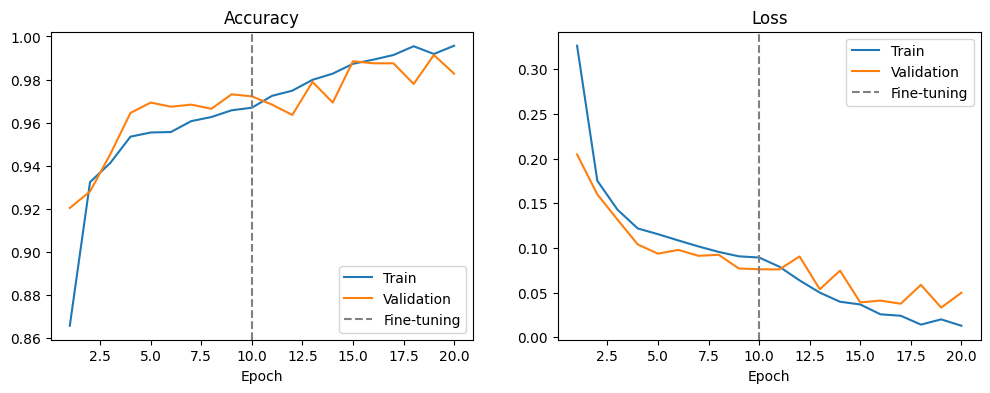

In [ ]:
acc = history.history["accuracy"] + history_fine.history["accuracy"]
val_acc = history.history["val_accuracy"] + history_fine.history["val_accuracy"]
loss = history.history["loss"] + history_fine.history["loss"]
val_loss = history.history["val_loss"] + history_fine.history["val_loss"]
epochs = range(1, len(acc) + 1)
start_fine = len(history.history["accuracy"])  # epoch where fine-tuning starts

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs, acc, label="Train")
plt.plot(epochs, val_acc, label="Validation")
plt.axvline(start_fine, color="gray", linestyle="--", label="Fine-tuning")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs, loss, label="Train")
plt.plot(epochs, val_loss, label="Validation")
plt.axvline(start_fine, color="gray", linestyle="--", label="Fine-tuning")
plt.title("Loss")
plt.xlabel("Epoch")
plt.legend()

plt.show()

## 8. Test the model

In [ ]:
cutoff = 0.5   # put the cutoff you picked here

# predictions for the whole test set
y_pred = (model.predict(test_ds) > cutoff).astype(int).flatten()

# real labels
y_true = np.concatenate([labels.numpy() for images, labels in test_ds]).flatten()

# accuracy with my cutoff
test_acc = np.mean(y_pred == y_true)
print("Test accuracy:", round(test_acc, 4))

print(classification_report(y_true, y_pred, target_names=class_names))

cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()

## 9. Try one image

In [ ]:
folder = os.path.join(data_dir, "test", "PNEUMONIA")
sample_path = os.path.join(folder, sorted(os.listdir(folder))[4])

img = tf.keras.utils.load_img(sample_path, target_size=img_size)
plt.imshow(img)
plt.axis("off")
plt.show()

x = np.expand_dims(tf.keras.utils.img_to_array(img), axis=0)
score = model.predict(x)[0][0]

print("Score:", round(float(score), 4))
if score > cutoff:
    print("Result: Pneumonia")
else:
    print("Result: Normal")